In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [15]:
df = pd.read_csv("train.csv")
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [13]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [17]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [19]:
#For dimensions
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 891
Total Columns: 12


In [21]:
#Displaying column names
print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
PassengerId
Survived
Pclass
Name
Sex
Age
SibSp
Parch
Ticket
Fare
Cabin
Embarked


In [23]:
df.info() #Statistical summary

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [25]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [27]:
df.describe(include='object')#Categorical data summary

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [29]:
#For misssing values
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [47]:
#For calculating missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")

print(missing_percentage.round(2)) 
print("Total Duplicate Records:", df.duplicated().sum())#For checking duplicate records
df = df.drop_duplicates()

Missing Value Percentage:
PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Embarked       0.0
dtype: float64
Total Duplicate Records: 0


In [49]:
df["Age"] = df["Age"].fillna(df["Age"].median())

print("Missing Age Values:", df["Age"].isnull().sum())

Missing Age Values: 0


In [51]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("Missing Embarked Values:", df["Embarked"].isnull().sum())

Missing Embarked Values: 0


In [41]:
df.drop(columns=['Cabin'], inplace=True)

print("Cabin column removed successfully!")

Cabin column removed successfully!


In [43]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())a

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [55]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (891, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [57]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1#creating new columns from existing data to make the analysis more meaningful.

df[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [59]:
df["IsAlone"] = np.where(df["FamilySize"] == 1, 1, 0)#Here, 1 means travelling alone and 0 means travelling with family.

df[["FamilySize", "IsAlone"]].head()

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1


In [61]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Adult", "Middle Aged", "Senior"])#Creating AgeGroup column

df[["Age", "AgeGroup"]].head(

,Age,AgeGroup
0,22.0,Adult
1,38.0,Middle Aged
2,26.0,Adult
3,35.0,Adult
4,35.0,Adult


In [63]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")#Extracting passenger titles from names
print(df["Title"].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64


In [67]:
#Statistical and categorical analysis
numerical_columns = df.select_dtypes(include=np.number).columns #Analysing numerical columns
print("Numerical Columns:")
print(numerical_columns.tolist())
print("Mean Values:")#Calculating mean
print(df[numerical_columns].mean())
print("Median Values:")#Calculating median
print(df[numerical_columns].median())
print("Standard Deviation:")#Calculating standard deviation
print(df[numerical_columns].std())
#Analysing categorical columns
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())

Numerical Columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Mean Values:
PassengerId    446.000000
Survived         0.383838
Pclass           2.308642
Age             29.361582
SibSp            0.523008
Parch            0.381594
Fare            32.204208
FamilySize       1.904602
IsAlone          0.602694
dtype: float64
Median Values:
PassengerId    446.0000
Survived         0.0000
Pclass           3.0000
Age             28.0000
SibSp            0.0000
Parch            0.0000
Fare            14.4542
FamilySize       1.0000
IsAlone          1.0000
dtype: float64
Standard Deviation:
PassengerId    257.353842
Survived         0.486592
Pclass           0.836071
Age             13.019697
SibSp            1.102743
Parch            0.806057
Fare            49.693429
FamilySize       1.613459
IsAlone          0.489615
dtype: float64

 Name
Name
Braund, Mr. Owen Harris                     1
Boulos, Mr. Hanna                           1
Frol

In [69]:
#Analyse survival count Where the Titanic dataset: 0 = Did not survive 1 = Survived
print("Survival Count:")
print(df["Survived"].value_counts())

print("\nSurvival Percentage:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [71]:
#Analysing survival by gender
gender_analysis = df.groupby("Sex")["Survived"].agg(
    Total_Passengers="count",
    Survivors="sum",
    Survival_Rate="mean"
)

gender_analysis["Survival_Rate"] *= 100

print(gender_analysis.round(2))

        Total_Passengers  Survivors  Survival_Rate
Sex                                               
female               314        233          74.20
male                 577        109          18.89


In [73]:
#Analysing survival by passenger class
class_analysis = df.groupby("Pclass")["Survived"].agg(
    Total_Passengers="count",
    Survivors="sum",
    Survival_Rate="mean"
)

class_analysis["Survival_Rate"] *= 100

print(class_analysis.round(2))

        Total_Passengers  Survivors  Survival_Rate
Pclass                                            
1                    216        136          62.96
2                    184         87          47.28
3                    491        119          24.24


In [75]:
#Analysing survival by age group
age_analysis = df.groupby("AgeGroup", observed=False)["Survived"].agg(
    Total_Passengers="count",
    Survivors="sum",
    Survival_Rate="mean"
)

age_analysis["Survival_Rate"] *= 100

print(age_analysis.round(2))

family_analysis = df.groupby("FamilySize")["Survived"].mean() * 100 #Analysing survival by family size

print("Survival Rate by Family Size:")
print(family_analysis.round(2))

             Total_Passengers  Survivors  Survival_Rate
AgeGroup                                               
Child                      69         40          57.97
Teenager                   70         30          42.86
Adult                     535        189          35.33
Middle Aged               195         78          40.00
Senior                     22          5          22.73
Survival Rate by Family Size:
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64


In [77]:
#Analysing survival by embarkation point
embarked_analysis = df.groupby("Embarked")["Survived"].agg(
    Total_Passengers="count",
    Survivors="sum",
    Survival_Rate="mean"
)

embarked_analysis["Survival_Rate"] *= 100

print(embarked_analysis.round(2))

          Total_Passengers  Survivors  Survival_Rate
Embarked                                            
C                      168         93          55.36
Q                       77         30          38.96
S                      646        219          33.90


In [79]:
#Analysing passenger fares
print("Fare Statistics:")
print(df["Fare"].describe())

print("\nHighest Fare:", df["Fare"].max())
print("Lowest Fare:", df["Fare"].min())
print("Average Fare:", df["Fare"].mean())

Fare Statistics:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

Highest Fare: 512.3292
Lowest Fare: 0.0
Average Fare: 32.204207968574636


In [81]:
#Analysing correlation with survival
correlation = df.select_dtypes(include=np.number).corr()

print("Correlation with Survival:")
print(correlation["Survived"].sort_values(ascending=False))

Correlation with Survival:
Survived       1.000000
Fare           0.257307
Parch          0.081629
FamilySize     0.016639
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.064910
IsAlone       -0.203367
Pclass        -0.338481
Name: Survived, dtype: float64


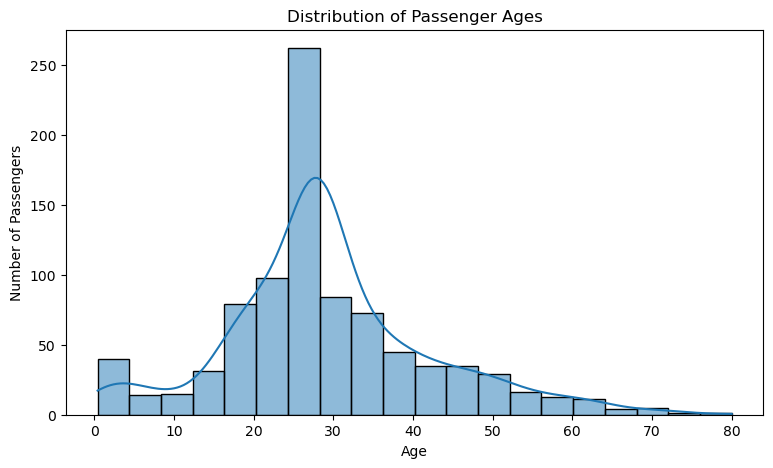

In [83]:
#Histogram of passenger ages
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

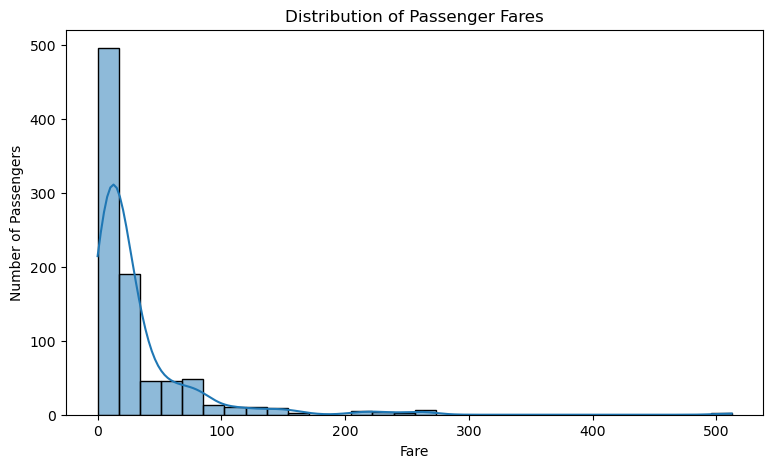

In [85]:
#Histogram of passenger fares
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Fare", bins=30, kde=True)

plt.title("Distribution of Passenger Fares")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

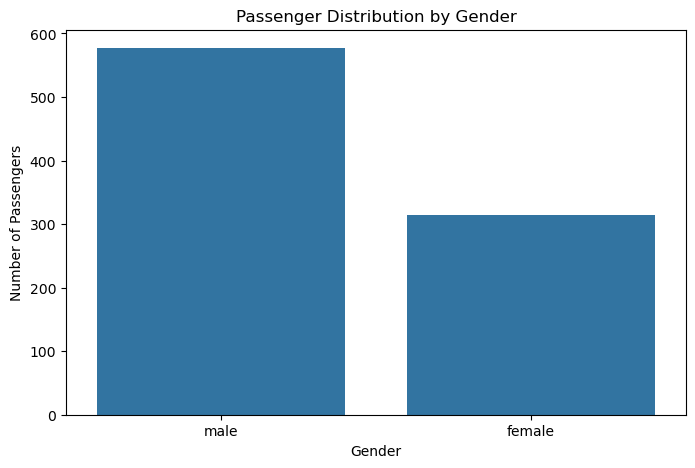

In [87]:
#Gender Distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Sex")

plt.title("Passenger Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

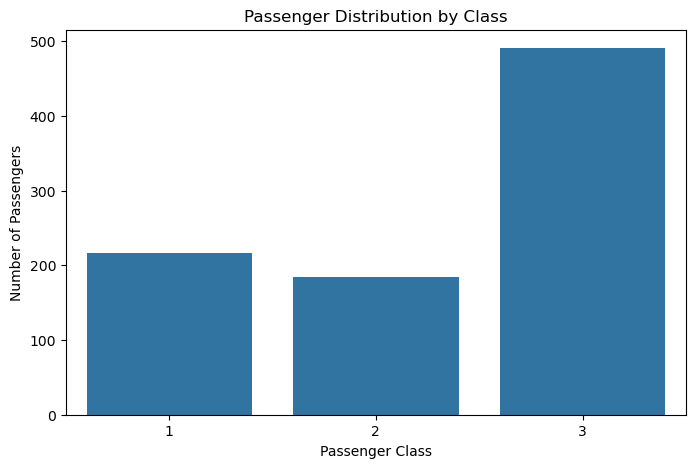

In [89]:
#Passenger class distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Pclass")

plt.title("Passenger Distribution by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

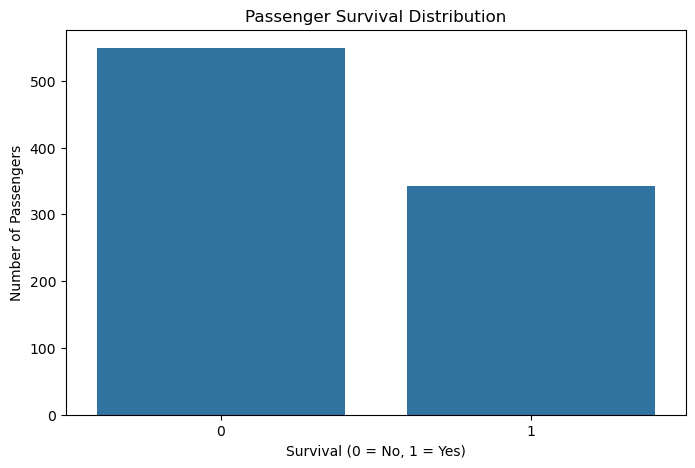

In [91]:
#Survival distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Survived")

plt.title("Passenger Survival Distribution")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

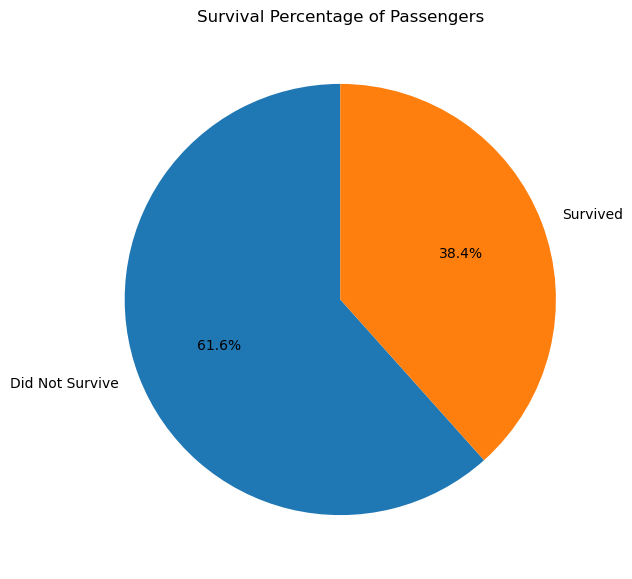

In [93]:
#Pie chart of survival percentage
survival_counts = df["Survived"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    survival_counts,
    labels=["Did Not Survive", "Survived"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Survival Percentage of Passengers")

plt.show()

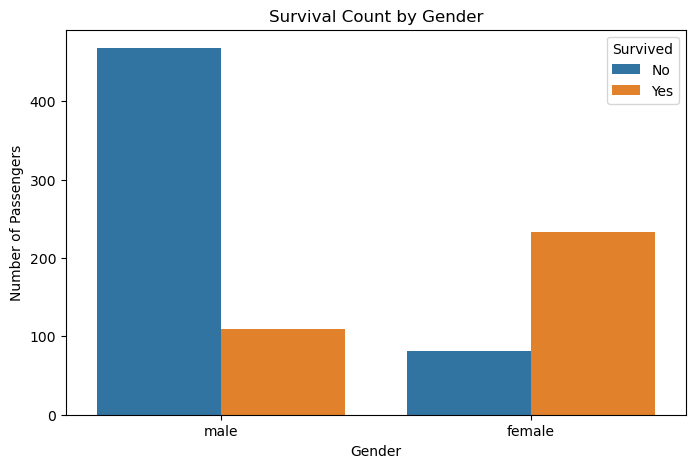

In [95]:
#Survival by gender
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()

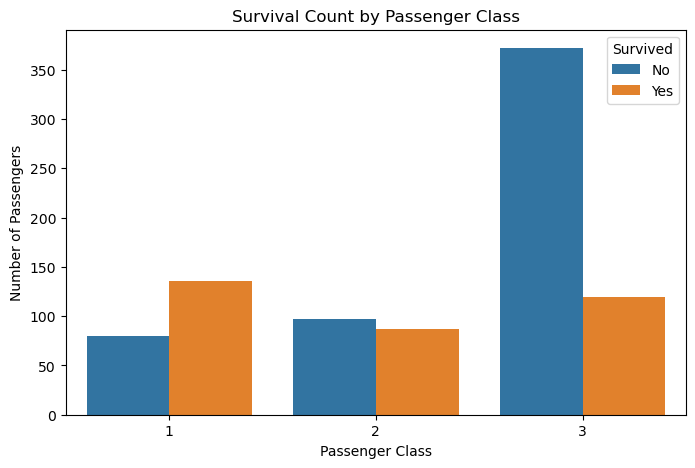

In [97]:
#Survival by passenger class
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Pclass", hue="Survived")

plt.title("Survival Count by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()

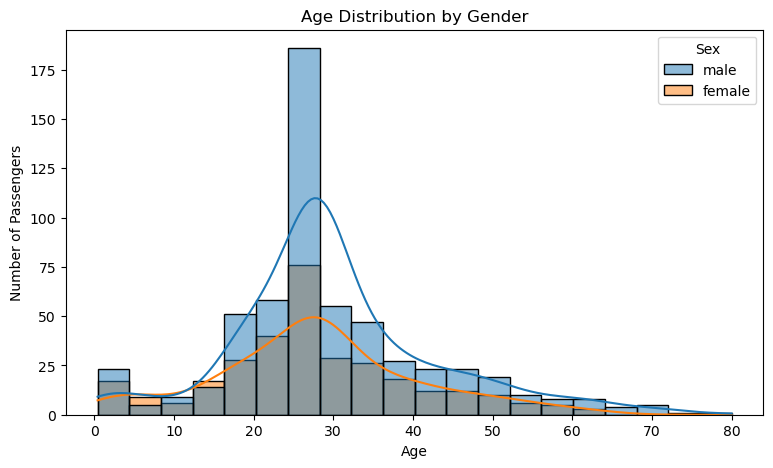

In [99]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Sex",
    bins=20,
    kde=True
)

plt.title("Age Distribution by Gender")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

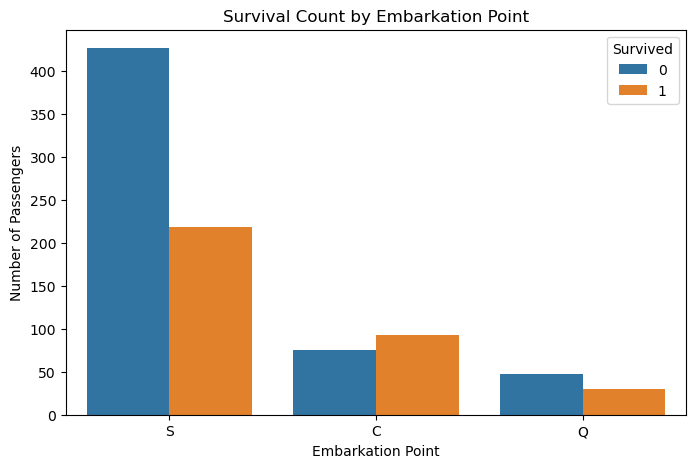

In [101]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Embarked", hue="Survived")

plt.title("Survival Count by Embarkation Point")
plt.xlabel("Embarkation Point")
plt.ylabel("Number of Passengers")

plt.show()

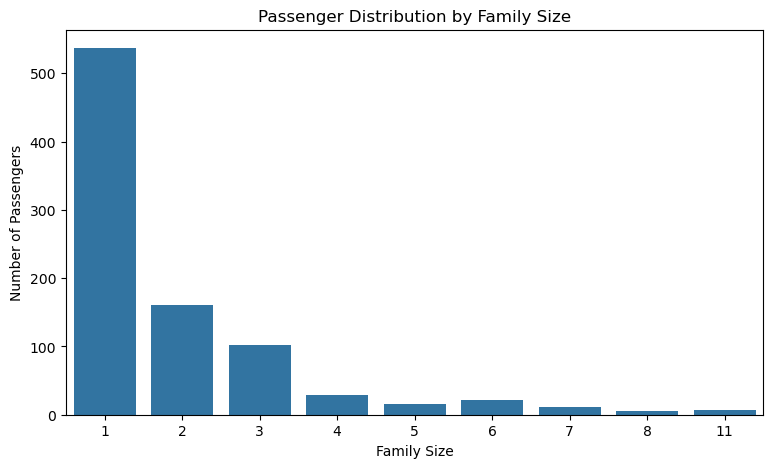

In [103]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="FamilySize")

plt.title("Passenger Distribution by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Number of Passengers")

plt.show()

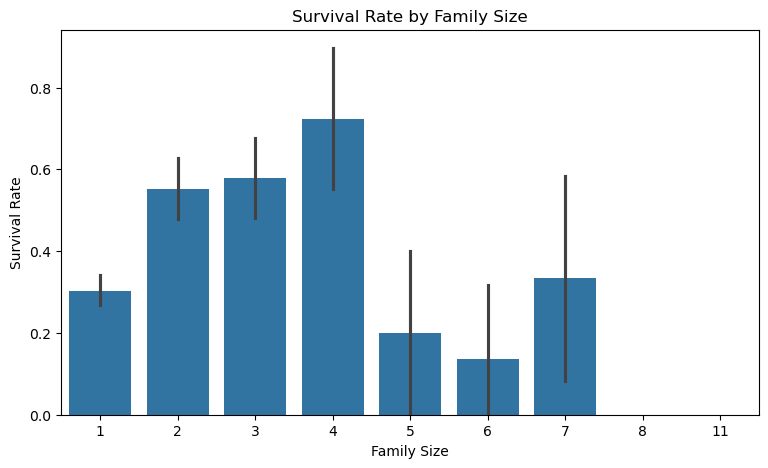

In [105]:
plt.figure(figsize=(9, 5))

sns.barplot(data=df, x="FamilySize", y="Survived")

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

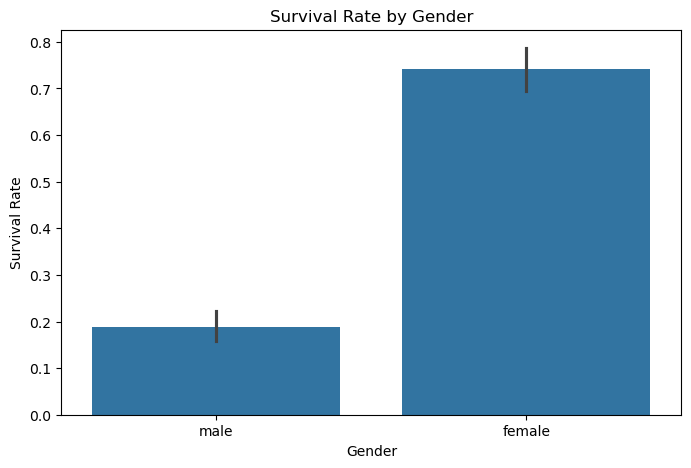

In [110]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Sex", y="Survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

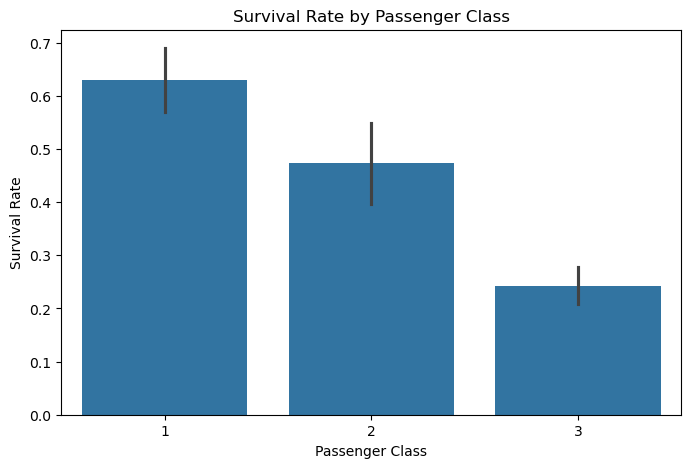

In [112]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Pclass", y="Survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

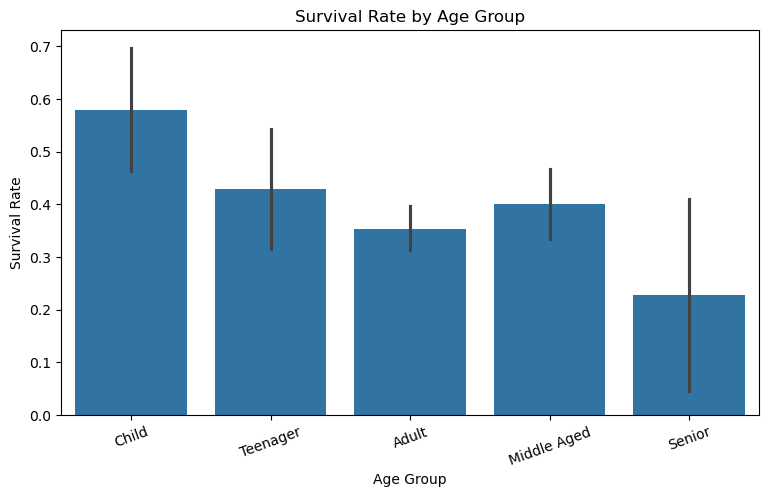

In [114]:
plt.figure(figsize=(9, 5))

sns.barplot(data=df, x="AgeGroup", y="Survived")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

plt.xticks(rotation=20)

plt.show()

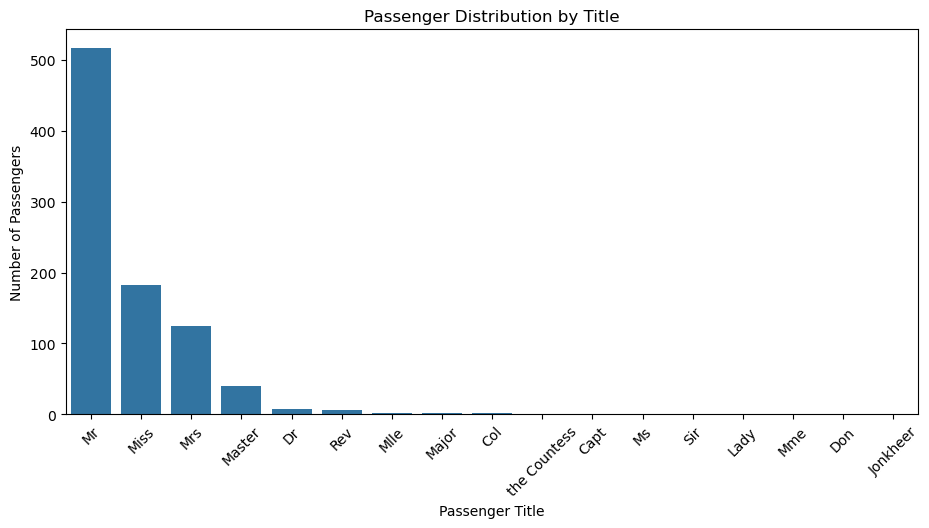

In [116]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="Title",
    order=df["Title"].value_counts().index
)

plt.title("Passenger Distribution by Title")
plt.xlabel("Passenger Title")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=45)

plt.show()

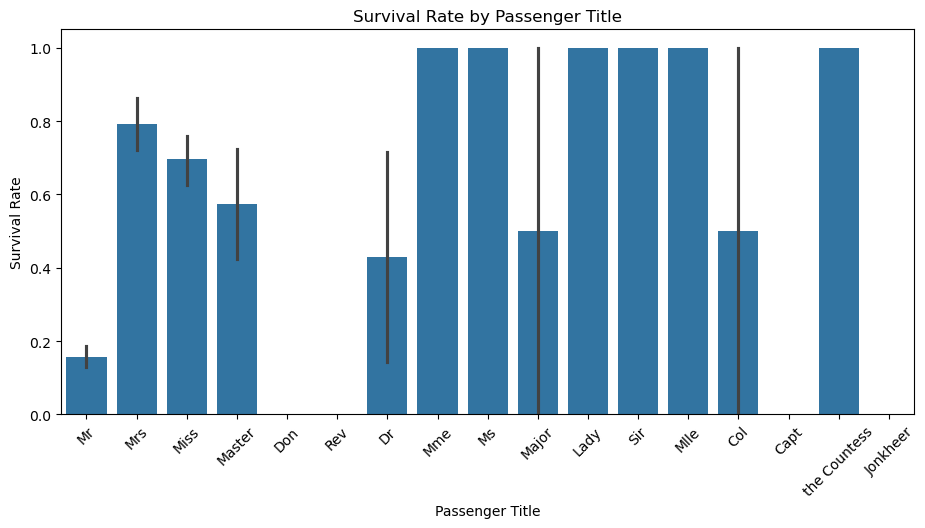

In [118]:
plt.figure(figsize=(11, 5))

sns.barplot(data=df, x="Title", y="Survived")

plt.title("Survival Rate by Passenger Title")
plt.xlabel("Passenger Title")
plt.ylabel("Survival Rate")
plt.xticks(rotation=45)

plt.show()

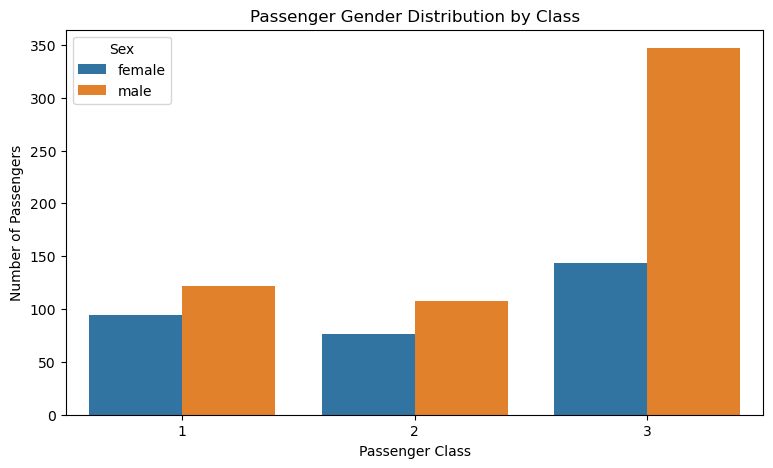

In [122]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Pclass", hue="Sex")

plt.title("Passenger Gender Distribution by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

In [124]:
print("========== TITANIC EDA SUMMARY ==========")

print("\nTotal Passengers:", len(df))

print("Total Survivors:", df["Survived"].sum())

print("Total Non-Survivors:", (df["Survived"] == 0).sum())

print(
    "Overall Survival Rate:",
    round(df["Survived"].mean() * 100, 2),
    "%"
)

print(
    "\nAverage Passenger Age:",
    round(df["Age"].mean(), 2)
)

print(
    "Average Passenger Fare:",
    round(df["Fare"].mean(), 2)
)

print("\nSurvival Rate by Gender:")
print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nSurvival Rate by Passenger Class:")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

print("\nSurvival Rate by Age Group:")
print((df.groupby("AgeGroup", observed=False)["Survived"].mean() * 100).round(2))

print("\nSurvival Rate by Family Size:")
print((df.groupby("FamilySize")["Survived"].mean() * 100).round(2))

========== TITANIC EDA SUMMARY ==========

Total Passengers: 891
Total Survivors: 342
Total Non-Survivors: 549
Overall Survival Rate: 38.38 %

Average Passenger Age: 29.36
Average Passenger Fare: 32.2

Survival Rate by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Survival Rate by Age Group:
AgeGroup
Child          57.97
Teenager       42.86
Adult          35.33
Middle Aged    40.00
Senior         22.73
Name: Survived, dtype: float64

Survival Rate by Family Size:
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64
